# Importações


In [ ]:
import pandas as pd
import plotly.express as px
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import mean_squared_error, r2_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV

In [ ]:
data = pd.read_csv('Final Dataset - State of Data 2024 - Kaggle - df_survey_2024.csv')

# Informações do conjunto de dados (opcional)




Nesta seção será abordada a análise exploratória dos dados.
A execução não interfere no treinamento do modelo.


In [ ]:
print(data.shape, ": tamanho do conjunto de dados")

(5217, 403)

In [ ]:
data.head() #Visualizando os dados

,0.a_token,0.d_data/hora_envio,1.a_idade,1.a.1_faixa_idade,1.b_genero,1.c_cor/raca/etnia,1.d_pcd,1.e_experiencia_profissional_prejudicada,1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.2_Sim, devido a minha Cor/Raça/Etnia",...,"8.d.3_Entrando em contato com os times de negócio para definição do problema, identificar a solução e apresentação de resultados.",8.d.4_Desenvolvendo modelos de Machine Learning com o objetivo de colocar em produção em sistemas (produtos de dados).,"8.d.5_Colocando modelos em produção, criando os pipelines de dados, APIs de consumo e monitoramento.","8.d.6_Cuidando da manutenção de modelos de Machine Learning já em produção, atuando no monitoramento, ajustes e refatoração quando necessário.","8.d.7_Realizando construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc.","8.d.8_Utilizando ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.","8.d.9_Criando e dando manutenção em ETLs, DAGs e automações de pipelines de dados.",8.d.10_Criando e gerenciando soluções de Feature Store e cultura de MLOps.,"8.d.11_Criando e mantendo a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",8.d.12_Treinando e aplicando LLM's para solucionar problemas de negócio.
0,reb94rv0msth7q4nreb94riaq80iz3yi,16/10/2024 11:19:17,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1zc66g69jjt49y32l1zc66g8wqj79m4e,16/10/2024 20:45:31,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,uu99wmam4n5kc2uu99wmydf0rk7l58f7,17/10/2024 18:10:59,18,17-21,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3ynsw7z0hl5hhpbfvaeqk73ynsw7z04l,22/10/2024 18:03:00,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,v6bji2ct5xckpl1uouv6bjiotkrf3b4f,23/10/2024 01:33:23,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data.info(verbose=True) #Para mostrar todas colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5217 entries, 0 to 5216
Data columns (total 403 columns):
 #    Column                                                                                                                                                                                               Dtype  
---   ------                                                                                                                                                                                               -----  
 0    0.a_token                                                                                                                                                                                            object 
 1    0.d_data/hora_envio                                                                                                                                                                                  object 
 2    1.a_idade                                 

In [ ]:
data.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
0.a_token,5217,5215,lb7gt5hdqqxuguv2lb7gto44mpk3ejha,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0.d_data/hora_envio,5217,5188,14/10/2024 17:37:10,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.a_idade,5217.0,NaN,NaN,NaN,32.358827,7.419433,18.0,27.0,31.0,36.0,68.0
1.a.1_faixa_idade,5217,9,30-34,1503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.b_genero,5217,4,Masculino,3968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
"8.d.8_Utilizando ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.",773.0,NaN,NaN,NaN,0.003881,0.062217,0.0,0.0,0.0,0.0,1.0
"8.d.9_Criando e dando manutenção em ETLs, DAGs e automações de pipelines de dados.",773.0,NaN,NaN,NaN,0.043984,0.205193,0.0,0.0,0.0,0.0,1.0
8.d.10_Criando e gerenciando soluções de Feature Store e cultura de MLOps.,773.0,NaN,NaN,NaN,0.009056,0.094791,0.0,0.0,0.0,0.0,1.0
"8.d.11_Criando e mantendo a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",773.0,NaN,NaN,NaN,0.011643,0.107342,0.0,0.0,0.0,0.0,1.0


Considerando o total de 5217 entrevistados, com a tabela acima é possível aferir que:

- O dataset contém dados de pessoas de 18 a 68 anos.
- Cerca de 75% dos participantes são do sexo masculino.
- Cerca de 67% são brancos.
- Dos que não vivem no Brasil, a maioria mora em Portugal.
- 30% ocupam cargos de nível sênior e 21% ocupam cargo de gestor.
- 180 são PCD (cerca de 3,45%)

In [ ]:
data['2.h_faixa_salarial'].unique()

array(['de R$ 1.001/mês a R$ 2.000/mês', 'Menos de R$ 1.000/mês', nan,
       'de R$ 6.001/mês a R$ 8.000/mês', 'de R$ 3.001/mês a R$ 4.000/mês',
       'de R$ 2.001/mês a R$ 3.000/mês', 'de R$ 4.001/mês a R$ 6.000/mês',
       'de R$ 8.001/mês a R$ 12.000/mês',
       'de R$ 12.001/mês a R$ 16.000/mês',
       'de R$ 30.001/mês a R$ 40.000/mês',
       'de R$ 20.001/mês a R$ 25.000/mês',
       'de R$ 16.001/mês a R$ 20.000/mês',
       'de R$ 25.001/mês a R$ 30.000/mês', 'Acima de R$ 40.001/mês'],
      dtype=object)

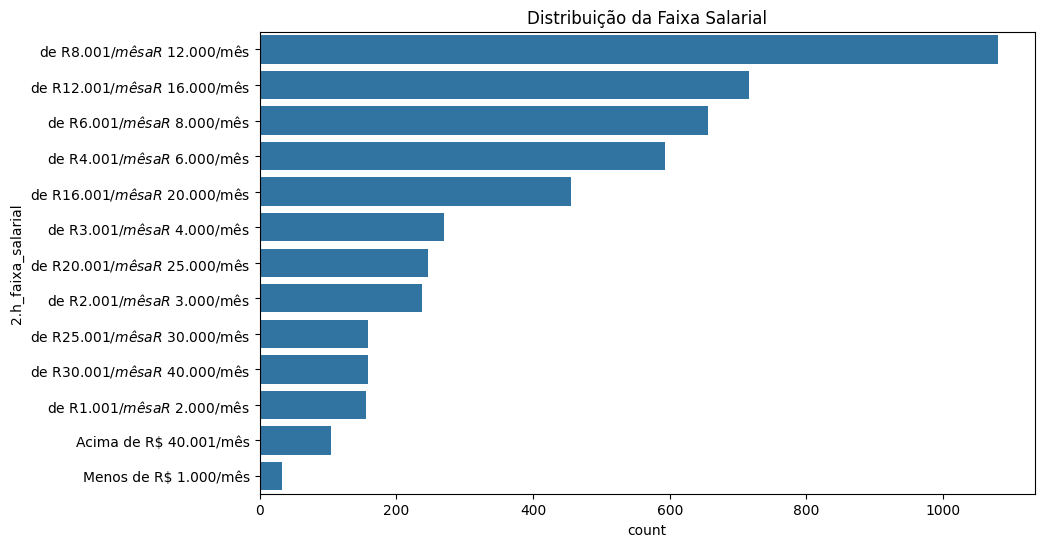

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(y=data['2.h_faixa_salarial'], order=data['2.h_faixa_salarial'].value_counts().index)
plt.title('Distribuição da Faixa Salarial')
plt.show()

Análise de correlação entre variáveis com a finalidade de identificar quais serão usadas para o treinamento

In [ ]:
corr = data.corr(numeric_only=True)
plt.figure(figsize=(120, 80))
sns.heatmap(corr,
            fmt=".2f",
            cmap='coolwarm',     # Cores: azul (negativa), branco (neutra), vermelho (positiva)
            linewidths=0.5,
            annot_kws={"size": 10})

plt.title('Matriz de Correlação entre Variáveis')
plt.show()

In [ ]:
corr_lista = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
                  .stack()
                  .sort_values(ascending=False))

print("Pares com maior correlação:")
corr_lista.head(10)

Pares com maior correlação:


,,0
4.d.6_Java,4.d.14_JavaScript,0.875656
4.g.27_Databricks,6.b.20_Databricks,0.840782
4.j.7_Looker,4.j.8_Looker Studio(Google Data Studio),0.808671
4.g.27_Databricks,7.b.20_Databricks,0.778917
4.g.22_Google BigQuery,4.h.2_Google Cloud (GCP),0.735242
4.j.16_Pentaho,7.b.8_Pentaho,0.717008
4.j.10_Alteryx,7.b.9_Alteryx,0.706831
4.g.6_CoachDB,6.b.5_Luigi,0.706467
8.a.12_Treino e aplico LLM's para solucionar problemas de negócio.,8.b.14_Utilizo LLM's para solucionar problemas de negócio.,0.700140
"8.a.8_Utilizo ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.","8.c.11_Ferramentas de estatística avançada como SPSS, SAS, etc.",0.657749


Os pares com maior correção estão relacionados a tecnologias utilizadas em conjunto.

In [ ]:
corr_lista = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
                  .stack()
                  .sort_values(ascending=True))

print("Pares com maior correlação:")
corr_lista.head(10)

Pares com maior correlação:


,,0
1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.3_Sim, devido a minha identidade de gênero",-0.686081
7.c.5_Minha empresa não utiliza essas ferramentas.,7.c.6_Não sei informar.,-0.605847
1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.2_Sim, devido a minha Cor/Raça/Etnia",-0.493135
4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade,4.m.4 A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade,-0.468665
4.j.18_Não utilizo nenhuma ferramenta de BI no trabalho,"8.c.1_Ferramentas de BI (PowerBI, Looker, Tableau, Qlik etc).",-0.452757
7.b.1_Scripts Python,7.b.21_Não utilizo ferramentas de ETL,-0.448347
4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade,4.m.3 Uso e pago pelas soluções de AI Generativa com foco em produtividade,-0.438196
7.b.2_SQL & Stored Procedures,7.b.21_Não utilizo ferramentas de ETL,-0.421545
4.d.3_Python,7.b.21_Não utilizo ferramentas de ETL,-0.415139
4.d.1_SQL,7.b.21_Não utilizo ferramentas de ETL,-0.386940


In [ ]:
data_corr = data.copy()
data_corr['faixa_codificada'] = data_corr['2.h_faixa_salarial'].astype('category').cat.codes
correlacoes_faixa = data_corr.corr(numeric_only=True)['faixa_codificada'].sort_values(ascending=False)

print("Correlação da Faixa Salarial com as outras variáveis:")
print(correlacoes_faixa)

Correlação da Faixa Salarial com as outras variáveis:
faixa_codificada                                                                                                      1.000000
7.a.3_Crio consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.       0.191907
3.g.6 Dados da empresa não estão prontos para uso de IA Generativa                                                    0.166019
3.g.8 Alta direção da empresa não vê valor ou não vê como prioridade                                                  0.164084
7.d.3_Criando consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.    0.148376
                                                                                                                        ...   
3.c.11_Gestão de pessoas                                                                                             -0.217984
3.b.10_ML Engineer/AI Engineer                           

In [ ]:
plot_data = correlacoes_faixa.drop('faixa_codificada').reset_index()
plot_data.columns = ['Variavel', 'Correlacao']

plt.figure(figsize=(100, 80))
sns.barplot(data=plot_data, x='Correlacao', y='Variavel', palette='RdBu_r')
plt.axvline(0, color='black', lw=1)

plt.title('Correlação das Variáveis com a Faixa Salarial', fontsize=15)
plt.xlabel('Coeficiente de Correlação', fontsize=12)
plt.ylabel('Variáveis', fontsize=12)
plt.tight_layout()
plt.show()

/tmp/ipykernel_410/3274330209.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_data, x='Correlacao', y='Variavel', palette='RdBu_r')


/tmp/ipykernel_410/799958990.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_data_filtered, x='Correlacao', y='Variavel', palette='RdBu_r')


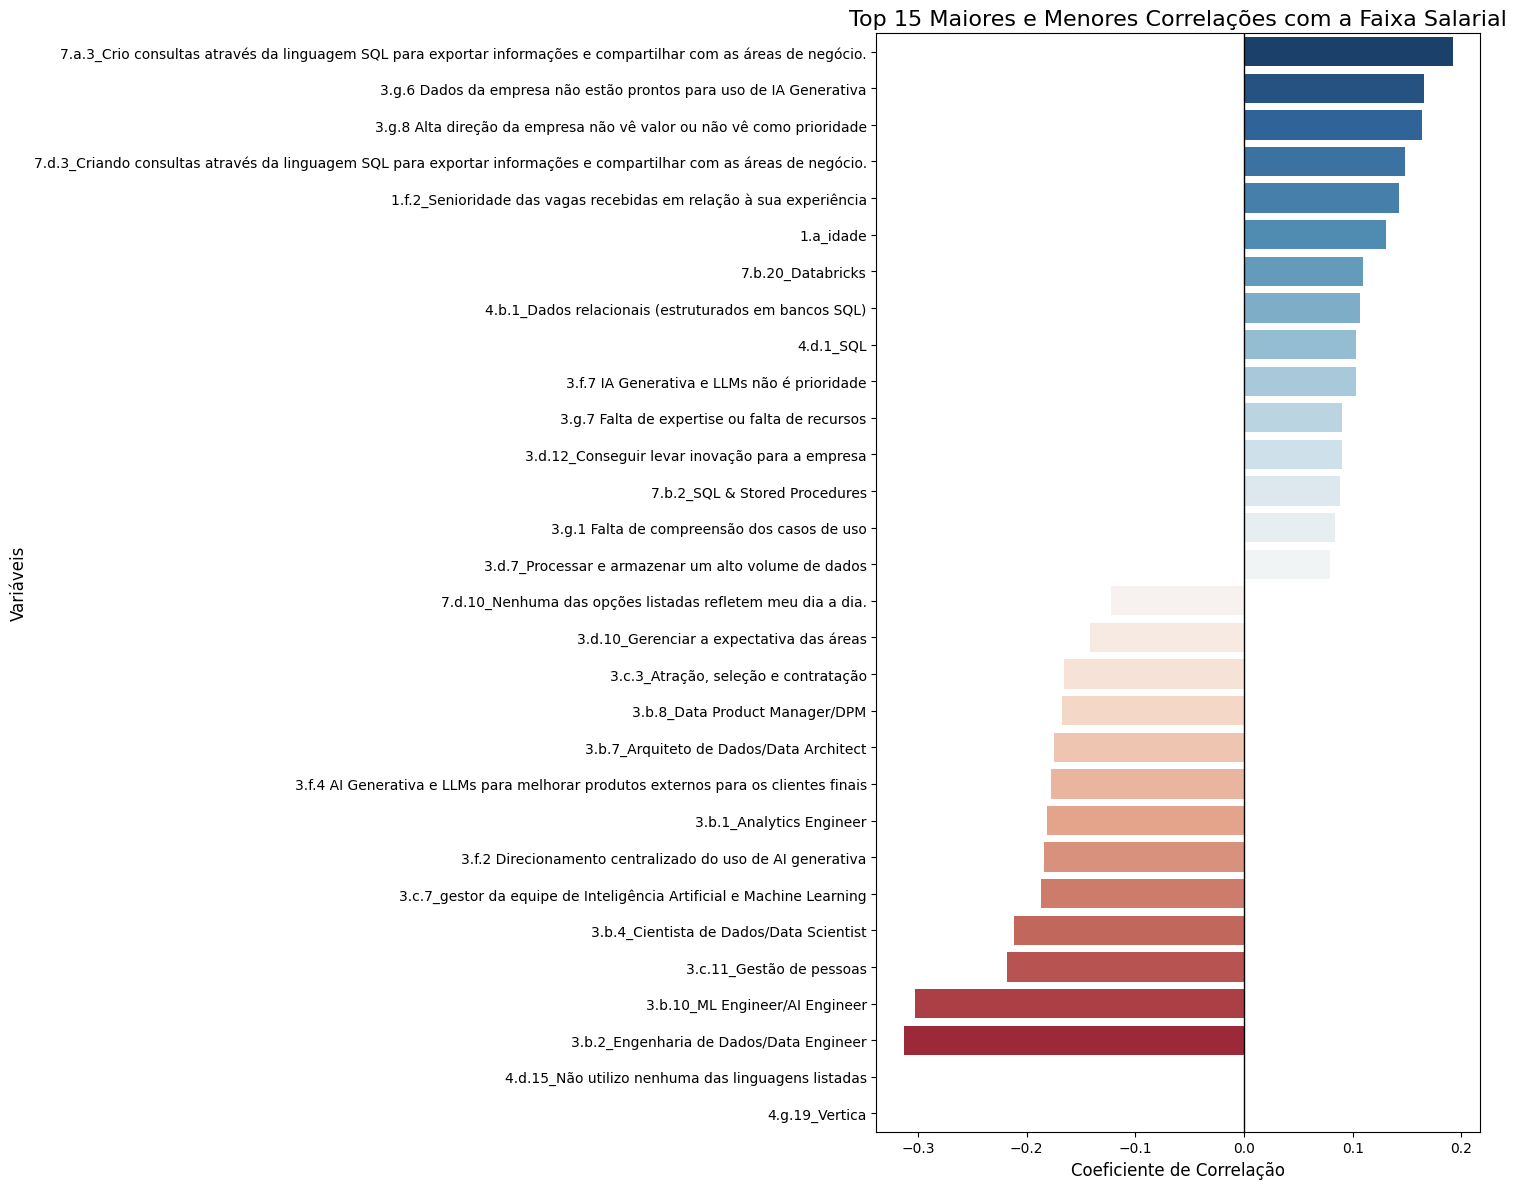

In [ ]:
top_15_correlations = correlacoes_faixa.drop('faixa_codificada').head(15)
bottom_15_correlations = correlacoes_faixa.drop('faixa_codificada').tail(15)

selected_correlations = pd.concat([top_15_correlations, bottom_15_correlations])

plot_data_filtered = selected_correlations.reset_index()
plot_data_filtered.columns = ['Variavel', 'Correlacao']

plt.figure(figsize=(15, 12))
sns.barplot(data=plot_data_filtered, x='Correlacao', y='Variavel', palette='RdBu_r')
plt.axvline(0, color='black', lw=1)

plt.title('Top 15 Maiores e Menores Correlações com a Faixa Salarial', fontsize=16)
plt.xlabel('Coeficiente de Correlação', fontsize=12)
plt.ylabel('Variáveis', fontsize=12)
plt.tight_layout()
plt.show()

# Treinamento do modelo

In [ ]:
data_corr = data.copy()
data_corr['faixa_codificada'] = data_corr['2.h_faixa_salarial'].astype('category').cat.codes
correlacoes_faixa = data_corr.corr(numeric_only=True)['faixa_codificada'].sort_values(ascending=False)
top_15_correlations = correlacoes_faixa.drop('faixa_codificada').head(15)
bottom_15_correlations = correlacoes_faixa.drop('faixa_codificada').tail(15)

print("Correlação da Faixa Salarial com as outras variáveis:")
print(correlacoes_faixa)

Correlação da Faixa Salarial com as outras variáveis:
faixa_codificada                                                                                                      1.000000
7.a.3_Crio consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.       0.126682
8.c.2_Planilhas (Excel, Google Sheets etc).                                                                           0.111910
1.f.2_Senioridade das vagas recebidas em relação à sua experiência                                                    0.108707
7.d.3_Criando consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.    0.108459
                                                                                                                        ...   
3.c.7_gestor da equipe de Inteligência Artificial e Machine Learning                                                 -0.144620
3.b.1_Analytics Engineer                                 

Acurácia Global: 31.23%

Relatório de Classificação:
              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        71
           0       0.25      0.05      0.08        21
           1       0.00      0.00      0.00         7
           2       0.40      0.06      0.11        31
           3       0.26      0.25      0.26       143
           4       0.22      0.20      0.21        91
           5       0.21      0.13      0.16        47
           6       0.22      0.14      0.17        49
           7       0.67      0.06      0.11        32
           8       0.29      0.07      0.12        54
           9       0.25      0.12      0.17        32
          10       0.24      0.32      0.28       119
          11       0.21      0.12      0.15       131
          12       0.29      0.56      0.38       216

    accuracy                           0.31      1044
   macro avg       0.32      0.22      0.23      1044
weighted avg       0.32    

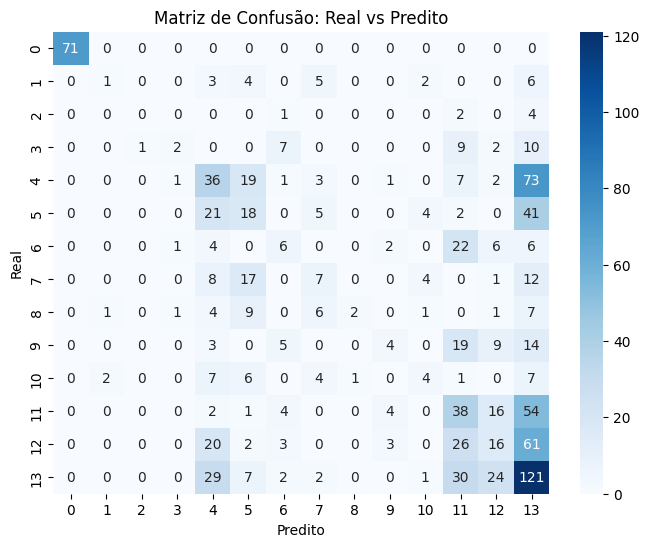

In [ ]:
# 1. Preparação dos dados
# Usando o DataFrame que já tem a 'faixa_codificada'
X = data_corr.select_dtypes(include=[np.number]).drop(columns=['faixa_codificada'])
y = data_corr['faixa_codificada']

# Preencher nulos para evitar erros no modelo
X = X.fillna(X.median())

# 2. Divisão Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Treinar o Classificador (Random Forest)
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# 4. Predições
y_pred = modelo_rf.predict(X_test)

# 5. Avaliação
print(f"Acurácia Global: {accuracy_score(y_test, y_pred):.2%}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# 6. Visualização: Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão: Real vs Predito')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

In [ ]:
data_corr['2.h_faixa_salarial'].value_counts().sort_index()

,count
2.h_faixa_salarial,
Acima de R$ 40.001/mês,104
Menos de R$ 1.000/mês,33
de R$ 1.001/mês a R$ 2.000/mês,155
de R$ 12.001/mês a R$ 16.000/mês,716
de R$ 16.001/mês a R$ 20.000/mês,456
de R$ 2.001/mês a R$ 3.000/mês,237
de R$ 2.001/mês a R$ 6.000/mês,593
de R$ 20.001/mês a R$ 25.000/mês,246
de R$ 25.001/mês a R$ 30.000/mês,159


In [ ]:
# Definindo o dicionário de mapeamento (De -> Para)
agrupamentos = {
    # Agrupando as faixas mais altas
    'Acima de R$ 40.001/mês': 'Acima de R$ 25.001/mês',
    'de R$ 30.001/mês a R$ 40.000/mês': 'Acima de R$ 25.001/mês',
    'de R$ 25.001/mês a R$ 30.000/mês': 'Acima de R$ 25.001/mês',

    # Agrupando as faixas mais baixas
    'Menos de R$ 1.000/mês': 'Até R$ 2.000/mês',
    'de R$ 1.001/mês a R$ 2.000/mês': 'Até R$ 2.000/mês',

    # Agrupando faixas intermediárias
    'de R$ 6.001/mês a R$ 8.000/mês': 'de R$ 6.001/mês a R$ 12.000/mês',
    'de R$ 8.001/mês a R$ 12.000/mês': 'de R$ 6.001/mês a R$ 12.000/mês'
}

# Aplicando a substituição na coluna
data_corr['2.h_faixa_salarial'] = data_corr['2.h_faixa_salarial'].replace(agrupamentos)

# Verificando como ficou a nova contagem
print(data_corr['2.h_faixa_salarial'].value_counts().sort_index())

2.h_faixa_salarial
Acima de R$ 25.001/mês               421
Até R$ 2.000/mês                     188
de R$ 12.001/mês a R$ 16.000/mês     716
de R$ 16.001/mês a R$ 20.000/mês     456
de R$ 2.001/mês a R$ 3.000/mês       237
de R$ 20.001/mês a R$ 25.000/mês     246
de R$ 3.001/mês a R$ 4.000/mês       270
de R$ 4.001/mês a R$ 6.000/mês       593
de R$ 6.001/mês a R$ 12.000/mês     1736
Name: count, dtype: int64


In [ ]:
novos_agrupamentos = {
    # Unindo o topo
    'de R$ 20.001/mês a R$ 25.000/mês': 'Acima de R$ 20.001/mês',
    'Acima de R$ 25.001/mês': 'Acima de R$ 20.001/mês',

    # Unindo a base intermediária
    'de R$ 2.001/mês a R$ 3.000/mês': 'de R$ 2.001/mês a R$ 4.000/mês',
    'de R$ 3.001/mês a R$ 4.000/mês': 'de R$ 2.001/mês a R$ 4.000/mês',

    # Unindo o alto
    'de R$ 12.001/mês a R$ 16.000/mês': 'de R$ 12.001/mês a R$ 20.000/mês',
    'de R$ 16.001/mês a R$ 20.000/mês': 'de R$ 12.001/mês a R$ 20.000/mês'
}

data_corr['2.h_faixa_salarial'] = data_corr['2.h_faixa_salarial'].replace(novos_agrupamentos)


# Verificando como ficou a nova contagem
print(data_corr['2.h_faixa_salarial'].value_counts().sort_index())

2.h_faixa_salarial
Acima de R$ 20.001/mês               667
Até R$ 2.000/mês                     188
de R$ 12.001/mês a R$ 20.000/mês    1172
de R$ 2.001/mês a R$ 4.000/mês       507
de R$ 4.001/mês a R$ 6.000/mês       593
de R$ 6.001/mês a R$ 12.000/mês     1736
Name: count, dtype: int64


Acurácia Global: 30.46%

Relatório de Classificação:
              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        71
           0       0.25      0.10      0.14        21
           1       0.50      0.14      0.22         7
           2       0.40      0.13      0.20        31
           3       0.23      0.21      0.22       143
           4       0.22      0.23      0.23        91
           5       0.28      0.17      0.21        47
           6       0.23      0.12      0.16        49
           7       0.14      0.03      0.05        32
           8       0.09      0.04      0.05        54
           9       0.11      0.06      0.08        32
          10       0.26      0.32      0.29       119
          11       0.24      0.15      0.19       131
          12       0.28      0.52      0.36       216

    accuracy                           0.30      1044
   macro avg       0.30      0.23      0.24      1044
weighted avg       0.29    

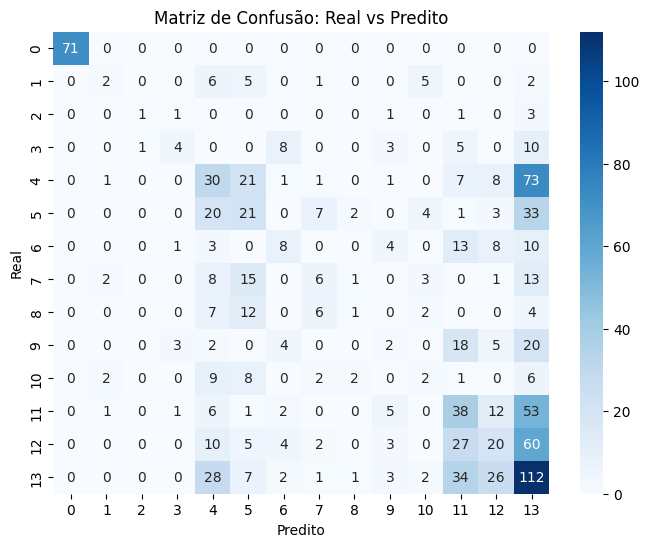

In [ ]:
X = data_corr.select_dtypes(include=[np.number]).drop(columns=['faixa_codificada'])
y = data_corr['faixa_codificada']

# Preencher nulos para evitar erros no modelo
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
modelo_rf = RandomForestClassifier(n_estimators=50, random_state=42, class_weight='balanced')
modelo_rf.fit(X_train, y_train)

y_pred = modelo_rf.predict(X_test)

print(f"Acurácia Global: {accuracy_score(y_test, y_pred):.2%}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão: Real vs Predito')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

In [ ]:
# Reduzir a classe majoritária drasticamente no treino
# Isso faz o modelo "parar de olhar tanto" para a classe 5
rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

# Treinar com Pesos Balanceados e limites de profundidade
# max_depth evita que o modelo decore os dados (overfitting)
modelo_v3 = RandomForestClassifier(
    n_estimators=80,
    max_depth=10,
    class_weight='balanced_subsample',
    random_state=42
)

modelo_v3.fit(X_train_res, y_train_res)

# Avaliar
y_pred = modelo_v3.predict(X_test)
print(f"Acurácia Global: {accuracy_score(y_test, y_pred):.2%}")
data_corr['faixa_codificada'] = data_corr['2.h_faixa_salarial'].astype('category').cat.codes
mapping_5 = dict(enumerate(data_corr['2.h_faixa_salarial'].astype('category').cat.categories))

classes_teste = np.unique(y_test)

print(classification_report(y_test, y_pred))

Acurácia Global: 20.59%
              precision    recall  f1-score   support

          -1       0.49      1.00      0.65        71
           0       0.14      0.24      0.18        21
           1       0.11      0.57      0.18         7
           2       0.06      0.16      0.09        31
           3       0.22      0.19      0.20       143
           4       0.11      0.05      0.07        91
           5       0.06      0.06      0.06        47
           6       0.19      0.12      0.15        49
           7       0.12      0.19      0.15        32
           8       0.08      0.13      0.10        54
           9       0.14      0.22      0.17        32
          10       0.15      0.08      0.10       119
          11       0.20      0.17      0.18       131
          12       0.27      0.18      0.21       216

    accuracy                           0.21      1044
   macro avg       0.17      0.24      0.18      1044
weighted avg       0.20      0.21      0.19      1044



In [ ]:
# Nova regra de agrupamento
def simplificar_faixa(valor):
    if valor in ['Até R$ 2.000/mês', 'de R$ 2.001/mês a R$ 4.000/mês']:
        return '1. Base (Até 4k)'
    elif valor in ['de R$ 4.001/mês a R$ 6.000/mês', 'de R$ 6.001/mês a R$ 12.000/mês']:
        return '2. Intermediário (4k-12k)'
    else:
        return '3. Especialista (Acima de 12k)'

data_corr['macro_faixa'] = data_corr['2.h_faixa_salarial'].apply(simplificar_faixa)
data_corr['macro_codificada'] = data_corr['macro_faixa'].astype('category').cat.codes

y_macro = data_corr['macro_codificada']
X_train, X_test, y_train, y_test = train_test_split(X, y_macro, test_size=0.2, random_state=42, stratify=y_macro)

modelo_macro = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
modelo_macro.fit(X_train, y_train)

y_pred = modelo_macro.predict(X_test)
nomes_macro = sorted(data_corr['macro_faixa'].unique())
print(classification_report(y_test, y_pred, target_names=nomes_macro))

                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.70      0.24      0.35       139
     2. Intermediário (4k-12k)       0.64      0.85      0.73       466
3. Especialista (Acima de 12k)       0.83      0.70      0.76       439

                      accuracy                           0.71      1044
                     macro avg       0.72      0.60      0.61      1044
                  weighted avg       0.72      0.71      0.69      1044



In [ ]:
# 1. Identificar as correlações com a nossa variável alvo
correlacoes = data_corr.corr(numeric_only=True)['macro_codificada'].drop('macro_codificada')

# 2. Pegar as 5 maiores e as 8 menores
top_5_pos = correlacoes.nlargest(5).index.tolist()
top_5_neg = correlacoes.nsmallest(8).index.tolist()

variaveis_selecionadas = top_5_pos + top_5_neg

print("Variáveis selecionadas para o modelo:")
for v in variaveis_selecionadas:
    corr_val = correlacoes[v]
    print(f"- {v}: {corr_val:.2f}")

# 3. Filtrar o X para usar apenas essas 10 colunas
X_filtrado = data_corr[variaveis_selecionadas].fillna(data_corr[variaveis_selecionadas].median())
y = data_corr['macro_codificada']

# 4. Novo Treino com o Dataset Enxuto
X_train, X_test, y_train, y_test = train_test_split(X_filtrado, y, test_size=0.2, random_state=42, stratify=y)

modelo_enxuto = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
modelo_enxuto.fit(X_train, y_train)

# 5. Avaliação
y_pred = modelo_enxuto.predict(X_test)
print("\nRelatório com as 10 principais variáveis:")
print(classification_report(y_test, y_pred, target_names=nomes_macro))

Variáveis selecionadas para o modelo:
- 3.b.2_Engenharia de Dados/Data Engineer: 0.34
- 1.a_idade: 0.34
- 3.c.11_Gestão de pessoas: 0.30
- 3.b.4_Cientista de Dados/Data Scientist: 0.29
- 3.b.7_Arquiteto de Dados/Data Architect: 0.26
- faixa_codificada: -0.55
- 4.c.7_Planilhas: -0.22
- 2.l.1_Remuneração/Salário: -0.20
- 4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade: -0.19
- 4.j.1_Microsoft PowerBI: -0.18
- 8.d.7_Realizando construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc.: -0.17
- 3.f.8 Não sei opinar sobre o uso de IA Generativa e LLMs na empresa: -0.16
- 2.o.7_Plano de carreira e oportunidades de crescimento: -0.15

Relatório com as 10 principais variáveis:
                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.98      0.97      0.97       139
     2. Intermediário (4k-12k)       1.00      1.00      1.00       466
3. Especialista (Acima de 12k)       0.99      0.99

# Testes de hiperparâmetros

In [ ]:
# Reusing X_filtrado and y_macro from the previous 3-class setup
X = X_filtrado
y = y_macro

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define the parameter grid to search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced']
}

# Instantiate the Grid Search model
grid_search_macro = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    verbose=2,
    scoring='f1_weighted'
)

# Fit the grid search to the training data
grid_search_macro.fit(X_train, y_train)

# Print the best parameters and best score
print(f"\nMelhores parâmetros encontrados para o modelo macro: {grid_search_macro.best_params_}")
print(f"Melhor score (F1-weighted) para o modelo macro: {grid_search_macro.best_score_:.2f}")

# Evaluate the best model found by GridSearchCV
best_macro_model = grid_search_macro.best_estimator_
y_pred_macro = best_macro_model.predict(X_test)

print("\nRelatório de Classificação do melhor modelo macro:")
# nomes_macro is available from cell -tFJCvx_md57
print(classification_report(y_test, y_pred_macro, target_names=nomes_macro))

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Melhores parâmetros encontrados para o modelo macro: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Melhor score (F1-weighted) para o modelo macro: 0.99

Relatório de Classificação do melhor modelo macro:
                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.99      0.97      0.98       139
     2. Intermediário (4k-12k)       1.00      1.00      1.00       466
3. Especialista (Acima de 12k)       0.99      1.00      0.99       439

                      accuracy                           0.99      1044
                     macro avg       0.99      0.99      0.99      1044
                  weighted avg       0.99      0.99      0.99      1044



In [ ]:
# 1. Aplicar a nova união para criar 5 categorias
uniao_intermediaria = {
    'de R$ 2.001/mês a R$ 4.000/mês': 'de R$ 2.001/mês a R$ 6.000/mês',
    'de R$ 4.001/mês a R$ 6.000/mês': 'de R$ 2.001/mês a R$ 6.000/mês'
}

# Aplicar a substituição na coluna original do DataFrame 'data_corr'
# Certifique-se de que 'data_corr' seja o DataFrame mais recente.
data_corr['2.h_faixa_salarial'] = data_corr['2.h_faixa_salarial'].replace(uniao_intermediaria)

# 2. Atualizar a codificação e o mapeamento para 5 categorias
data_corr['faixa_codificada'] = data_corr['2.h_faixa_salarial'].astype('category').cat.codes
mapping_5 = dict(enumerate(data_corr['2.h_faixa_salarial'].astype('category').cat.categories))

# 3. Selecionar as variáveis (usando as últimas selecionadas ou re-calculando)
# Re-calculando correlações para as 5 categorias
correlacoes = data_corr.corr(numeric_only=True)['faixa_codificada'].drop('faixa_codificada')
# Selecting top 5 positive and top 5 negative correlations
features_selecionadas = correlacoes.nlargest(5).index.tolist() + correlacoes.nsmallest(5).index.tolist()

# Explicitly remove 'faixa_codificada' if it was selected, as it is a target-like variable.
if 'faixa_codificada' in features_selecionadas:
    features_selecionadas.remove('faixa_codificada')

# 4. Preparar X e y com as 5 categorias
X = data_corr[features_selecionadas].fillna(data_corr[features_selecionadas].median())
y = data_corr['faixa_codificada']

# 5. Divisão Treino e Teste com Estratificação
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define the parameter grid to search
param_grid = {
    'n_estimators': [100, 200, 300],  # Number of trees in the forest
    'max_depth': [10, 20, 30, None],  # Maximum depth of the tree
    'min_samples_leaf': [1, 2, 4],    # Minimum number of samples required to be at a leaf node
    'class_weight': ['balanced']      # Keep balanced class weight
}

# Instantiate the Grid Search model
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42), # Use a new RandomForestClassifier instance
    param_grid=param_grid,
    cv=5, # 5-fold cross-validation
    n_jobs=-1, # Use all available cores
    verbose=2, # Output progress
    scoring='f1_weighted' # Metric to optimize
)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Print the best parameters and best score
print(f"\nMelhores parâmetros encontrados: {grid_search.best_params_}")
print(f"Melhor score (F1-weighted): {grid_search.best_score_:.2f}")

# Pega o melhor modelo
best_rf_model = grid_search.best_estimator_

# Fazer predições com o melhor modelo
y_pred_best = best_rf_model.predict(X_test)

# Gerar os nomes das classes para o classification_report
# Primeiro, obter as classes únicas presentes em y_test
unique_classes_in_y_test = np.unique(y_test)

# Criar a lista de target_names baseada em mapping_5 e adicionar o tratamento para -1
target_names_list = []
for class_code in unique_classes_in_y_test:
    if class_code == -1:
        target_names_list.append('Não Mapeado/NaN') # Label for unmapped/NaN values
    elif class_code in mapping_5:
        target_names_list.append(mapping_5[class_code])
    else:
        target_names_list.append(f'Classe Desconhecida {class_code}') # Fallback for any unexpected class

# Verificar o melhor modelo
print("\nRelatório de Classificação com o melhor modelo:")
print(classification_report(y_test, y_pred_best, target_names=target_names_list))

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Melhores parâmetros encontrados: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
Melhor score (F1-weighted): 0.54

Relatório de Classificação com o melhor modelo:
                                  precision    recall  f1-score   support

                 Não Mapeado/NaN       0.49      1.00      0.65        71
          Acima de R$ 20.001/mês       0.57      0.50      0.54       133
                Até R$ 2.000/mês       0.26      0.97      0.41        38
de R$ 12.001/mês a R$ 20.000/mês       0.75      0.56      0.64       235
  de R$ 2.001/mês a R$ 6.000/mês       0.38      0.01      0.03       220
 de R$ 6.001/mês a R$ 12.000/mês       0.76      0.99      0.86       347

                        accuracy                           0.63      1044
                       macro avg       0.53      0.67      0.52      1044
                    weighted avg       0.61      0.63      0.56 